# Phase 3 — Second training run vs the reference run

1. **Freeze the reference** — copy the colleague's `runs/train/full/weights/best.pt` to `models/` so no later run can overwrite it.
2. **Check the lots** — which parking lots are in train / val / test (is test an unseen lot?).
3. **Train** — run A: full schedule (no early stopping, `max_det` raised); run B: run A + vertical flip.
4. **Compare** — same test split for every model: mAP, and count MAE / RMSE / bias on *all* 484 test images,
   at `conf=0.25` and at the threshold tuned on val; per source; head to head per image.

In [2]:
import shutil
import sys
from pathlib import Path

for p in (Path("src/3_phase").resolve(), Path("src/2_phase").resolve(), Path("src").resolve()):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import compare
import full_run
from common import run_logging, train_eval, training

## 1. Freeze the reference model

In [4]:
REF = Path("models/reference_full_best.pt")
if not REF.exists():
    shutil.copy2("runs/train/full/weights/best.pt", REF)
print(REF, f"{REF.stat().st_size / 1e6:.1f} MB")

models/reference_full_best.pt 5.6 MB


## 2. Parking lots per split

In [3]:
compare.lots_per_split()

split,train,val,test
lot,,,
carpk:GF1,366,32,0
carpk:GF2,312,36,0
carpk:NTU,214,29,0
carpk:TPZ,0,0,459
pucpr,88,12,25


## 3. Train
Each run is ~100 epochs × ~8 s ≈ 15 min on the 2 GPUs. Run B only changes `flipud`, so A vs B isolates the augmentation
and reference vs A isolates the schedule.

In [6]:
train_eval.make_subset()
runs = {
    "A_full_schedule": training.train_args(name="v2_full_schedule", train_eval=True),
    "B_flipud":        training.train_args(name="v2_flipud", train_eval=True, flipud=0.5),
}
run_dirs = {}
for label, args in runs.items():
    run_dirs[label] = training.launch(args)
    print(label, *run_logging.grep_log(run_dirs[label], "final_best"), *run_logging.grep_log(run_dirs[label], "# finished"))

A_full_schedule final_best metrics/precision(B)=0.99215 metrics/recall(B)=0.99526 metrics/mAP50(B)=0.99426 metrics/mAP50-95(B)=0.80126 # finished 2026-10-27 16:48:02 best_epoch=89 best=/home/mariusz_godlewski/car_recognition/runs/train/v2_full_schedule/weights/best.pt last=/home/mariusz_godlewski/car_recognition/runs/train/v2_full_schedule/weights/last.pt
B_flipud final_best metrics/precision(B)=0.99132 metrics/recall(B)=0.9937 metrics/mAP50(B)=0.99407 metrics/mAP50-95(B)=0.79532 # finished 2026-10-27 17:00:18 best_epoch=100 best=/home/mariusz_godlewski/car_recognition/runs/train/v2_flipud/weights/best.pt last=/home/mariusz_godlewski/car_recognition/runs/train/v2_flipud/weights/last.pt


In [16]:
run_dirs["ref"] = training.launch(training.train_args(name="ref", train_eval=True))
print(label, *run_logging.grep_log(run_dirs["ref"], "final_best"), *run_logging.grep_log(run_dirs["ref"], "# finished"))

B_flipud final_best metrics/precision(B)=0.99215 metrics/recall(B)=0.99526 metrics/mAP50(B)=0.99426 metrics/mAP50-95(B)=0.80126 # finished 2026-10-27 17:31:13 best_epoch=89 best=/home/mariusz_godlewski/car_recognition/runs/train/ref/weights/best.pt last=/home/mariusz_godlewski/car_recognition/runs/train/ref/weights/last.pt


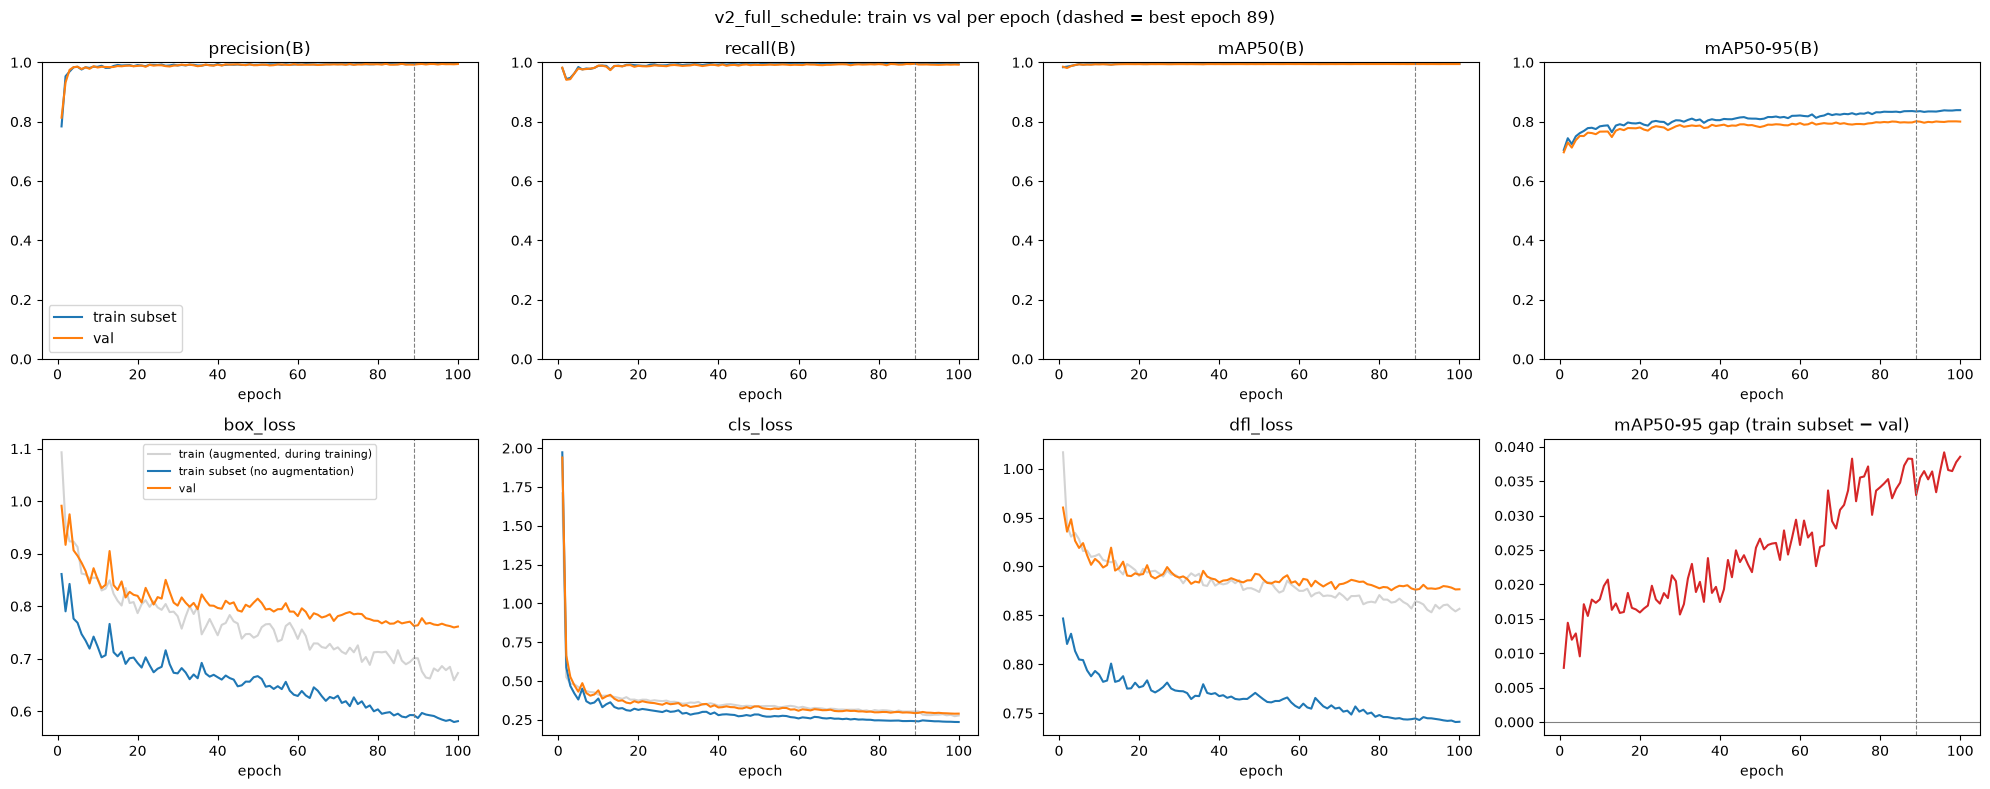

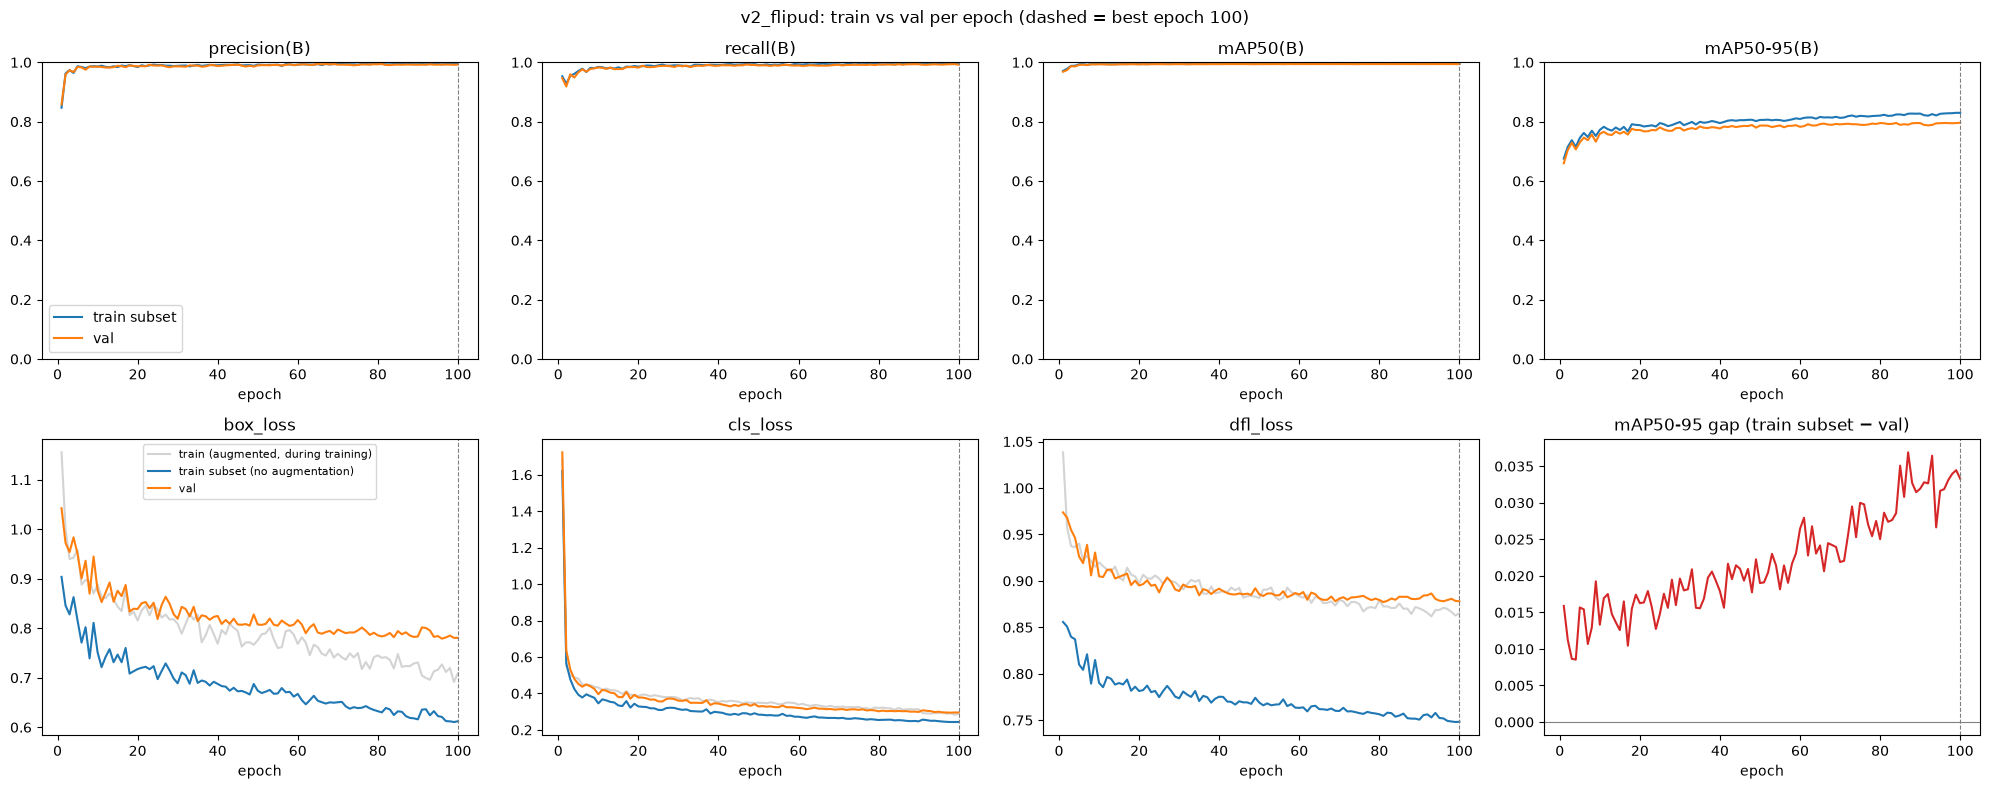

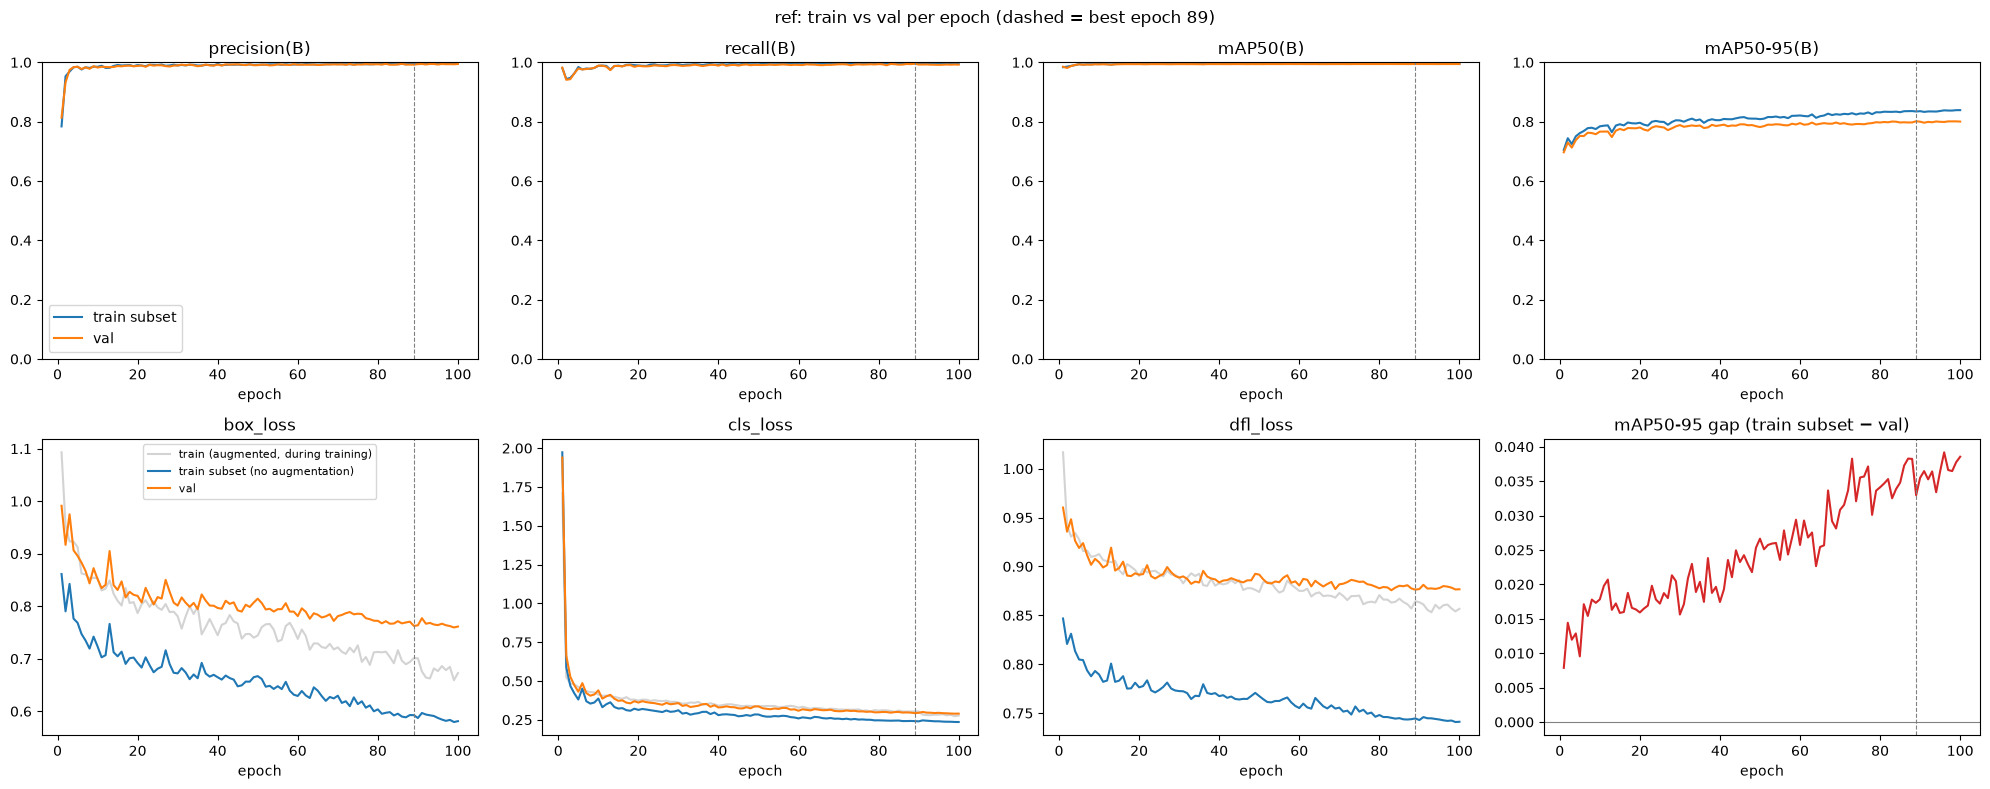

In [17]:
for d in run_dirs.values():
    full_run.plot_curves(d);

## 4. Compare on the test split

In [18]:
models = {**{k: d / "weights" / "best.pt" for k, d in run_dirs.items()}}
result = compare.compare(models)
result["summary"].astype(float).round(3)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 15946MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9031.4±611.3 MB/s, size: 1348.8 KB)
val: Scanning /home/mariusz_godlewski/car_recognition/datasets/yolo/labels/test.cache... 484 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 484/484 338.3Mit/s 0.0s
val: /home/mariusz_godlewski/car_recognition/datasets/yolo/images/test/carpk__20161225_TPZ_00437.png: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 6.9it/s 4.5s<0.2s
                   all        484      51419      0.984      0.957       0.98      0.704
Speed: 0.7ms preprocess, 3.2ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /home/mariusz_godlewski/car_recognition/runs/compare/A_full_schedule_test
Ultralytics 8.4.185 🚀 Python-3.12.3

,precision(B),recall(B),mAP50(B),mAP50-95(B),tuned conf,MAE @0.25,RMSE @0.25,bias @0.25,rel_err_% @0.25,MAE @tuned,RMSE @tuned,bias @tuned,rel_err_% @tuned
A_full_schedule,0.984,0.957,0.980,0.704,0.525,3.428,4.762,1.382,3.226,3.665,5.205,-3.169,3.450
B_flipud,0.984,0.960,0.981,0.708,0.500,3.326,5.079,1.128,3.131,3.721,5.057,-2.994,3.503
ref,0.984,0.957,0.980,0.704,0.525,3.428,4.762,1.382,3.226,3.665,5.205,-3.169,3.450


In [9]:
result['by_source'].round(2)

images   MAE  RMSE  bias  rel_err_%
model           source                                     
reference       carpk      459  3.21  4.60 -1.72       3.10
                pucpr       25  2.24  3.73 -0.40       1.43
A_full_schedule carpk      459  3.79  5.32 -3.33       3.66
                pucpr       25  1.44  2.33 -0.24       0.92
B_flipud        carpk      459  3.80  5.13 -3.12       3.67
                pucpr       25  2.32  3.46 -0.72       1.48

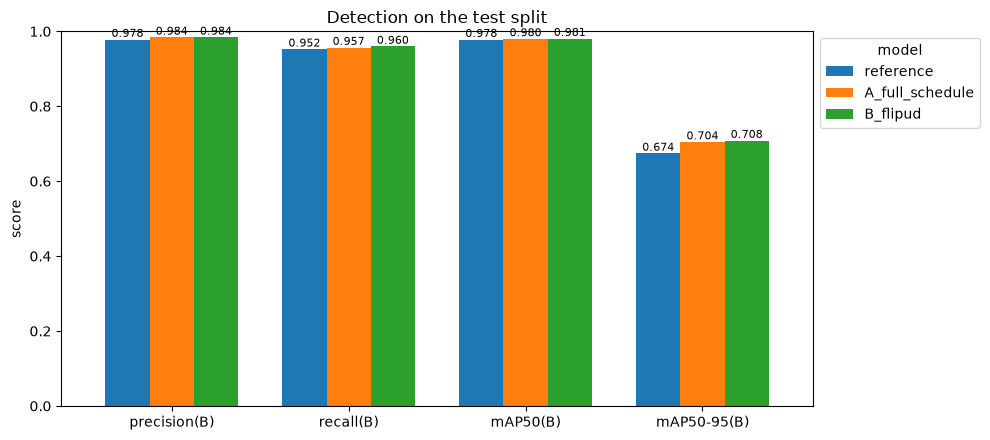

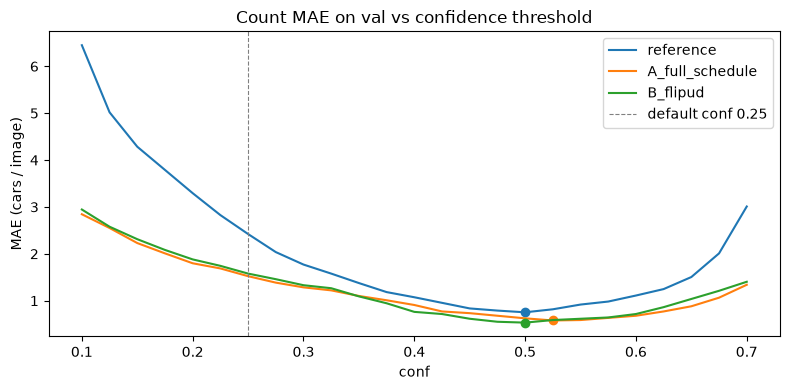

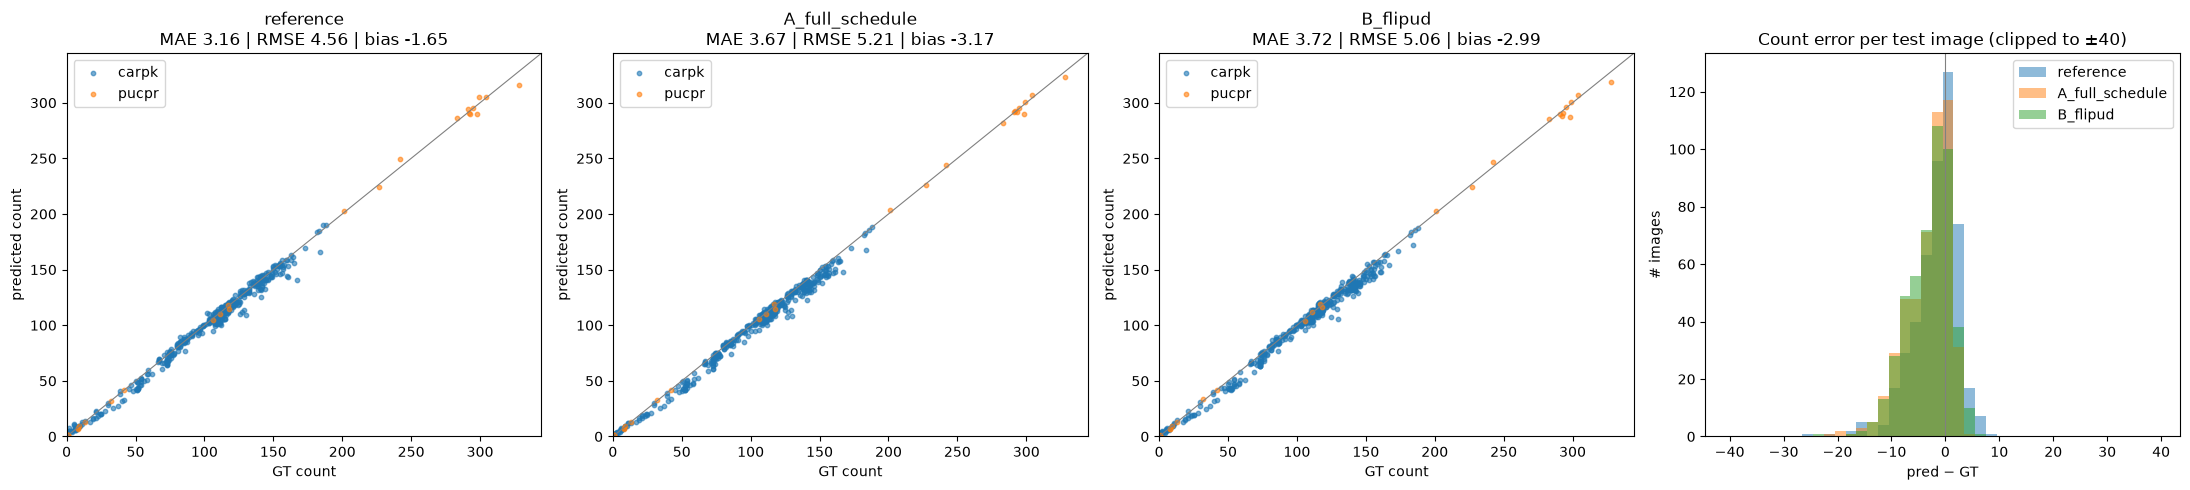

In [10]:
compare.plot_summary(result); compare.plot_sweeps(result); compare.plot_counts(result);

Images where the new model and the reference disagree most (val-tuned thresholds):

In [11]:
h2h = compare.head_to_head(result, "B_flipud", "reference")
h2h.head(15)

closer
reference    219
B_flipud     161
tie          104


,source,gt,pred B_flipud,pred reference,|err| B_flipud,|err| reference,closer
image,,,,,,,
carpk__20161225_TPZ_00244,carpk,130,106,109,24,21,reference
carpk__20161225_TPZ_00241,carpk,125,107,122,18,3,reference
carpk__20161225_TPZ_00284,carpk,144,129,141,15,3,reference
carpk__20161225_TPZ_00355,carpk,141,126,125,15,16,B_flipud
carpk__20161225_TPZ_00354,carpk,129,115,114,14,15,B_flipud
carpk__20161225_TPZ_00269,carpk,155,142,155,13,0,reference
carpk__20161225_TPZ_00441,carpk,161,148,143,13,18,B_flipud
carpk__20161225_TPZ_00415,carpk,167,154,141,13,26,B_flipud
carpk__20161225_TPZ_00250,carpk,157,144,151,13,6,reference


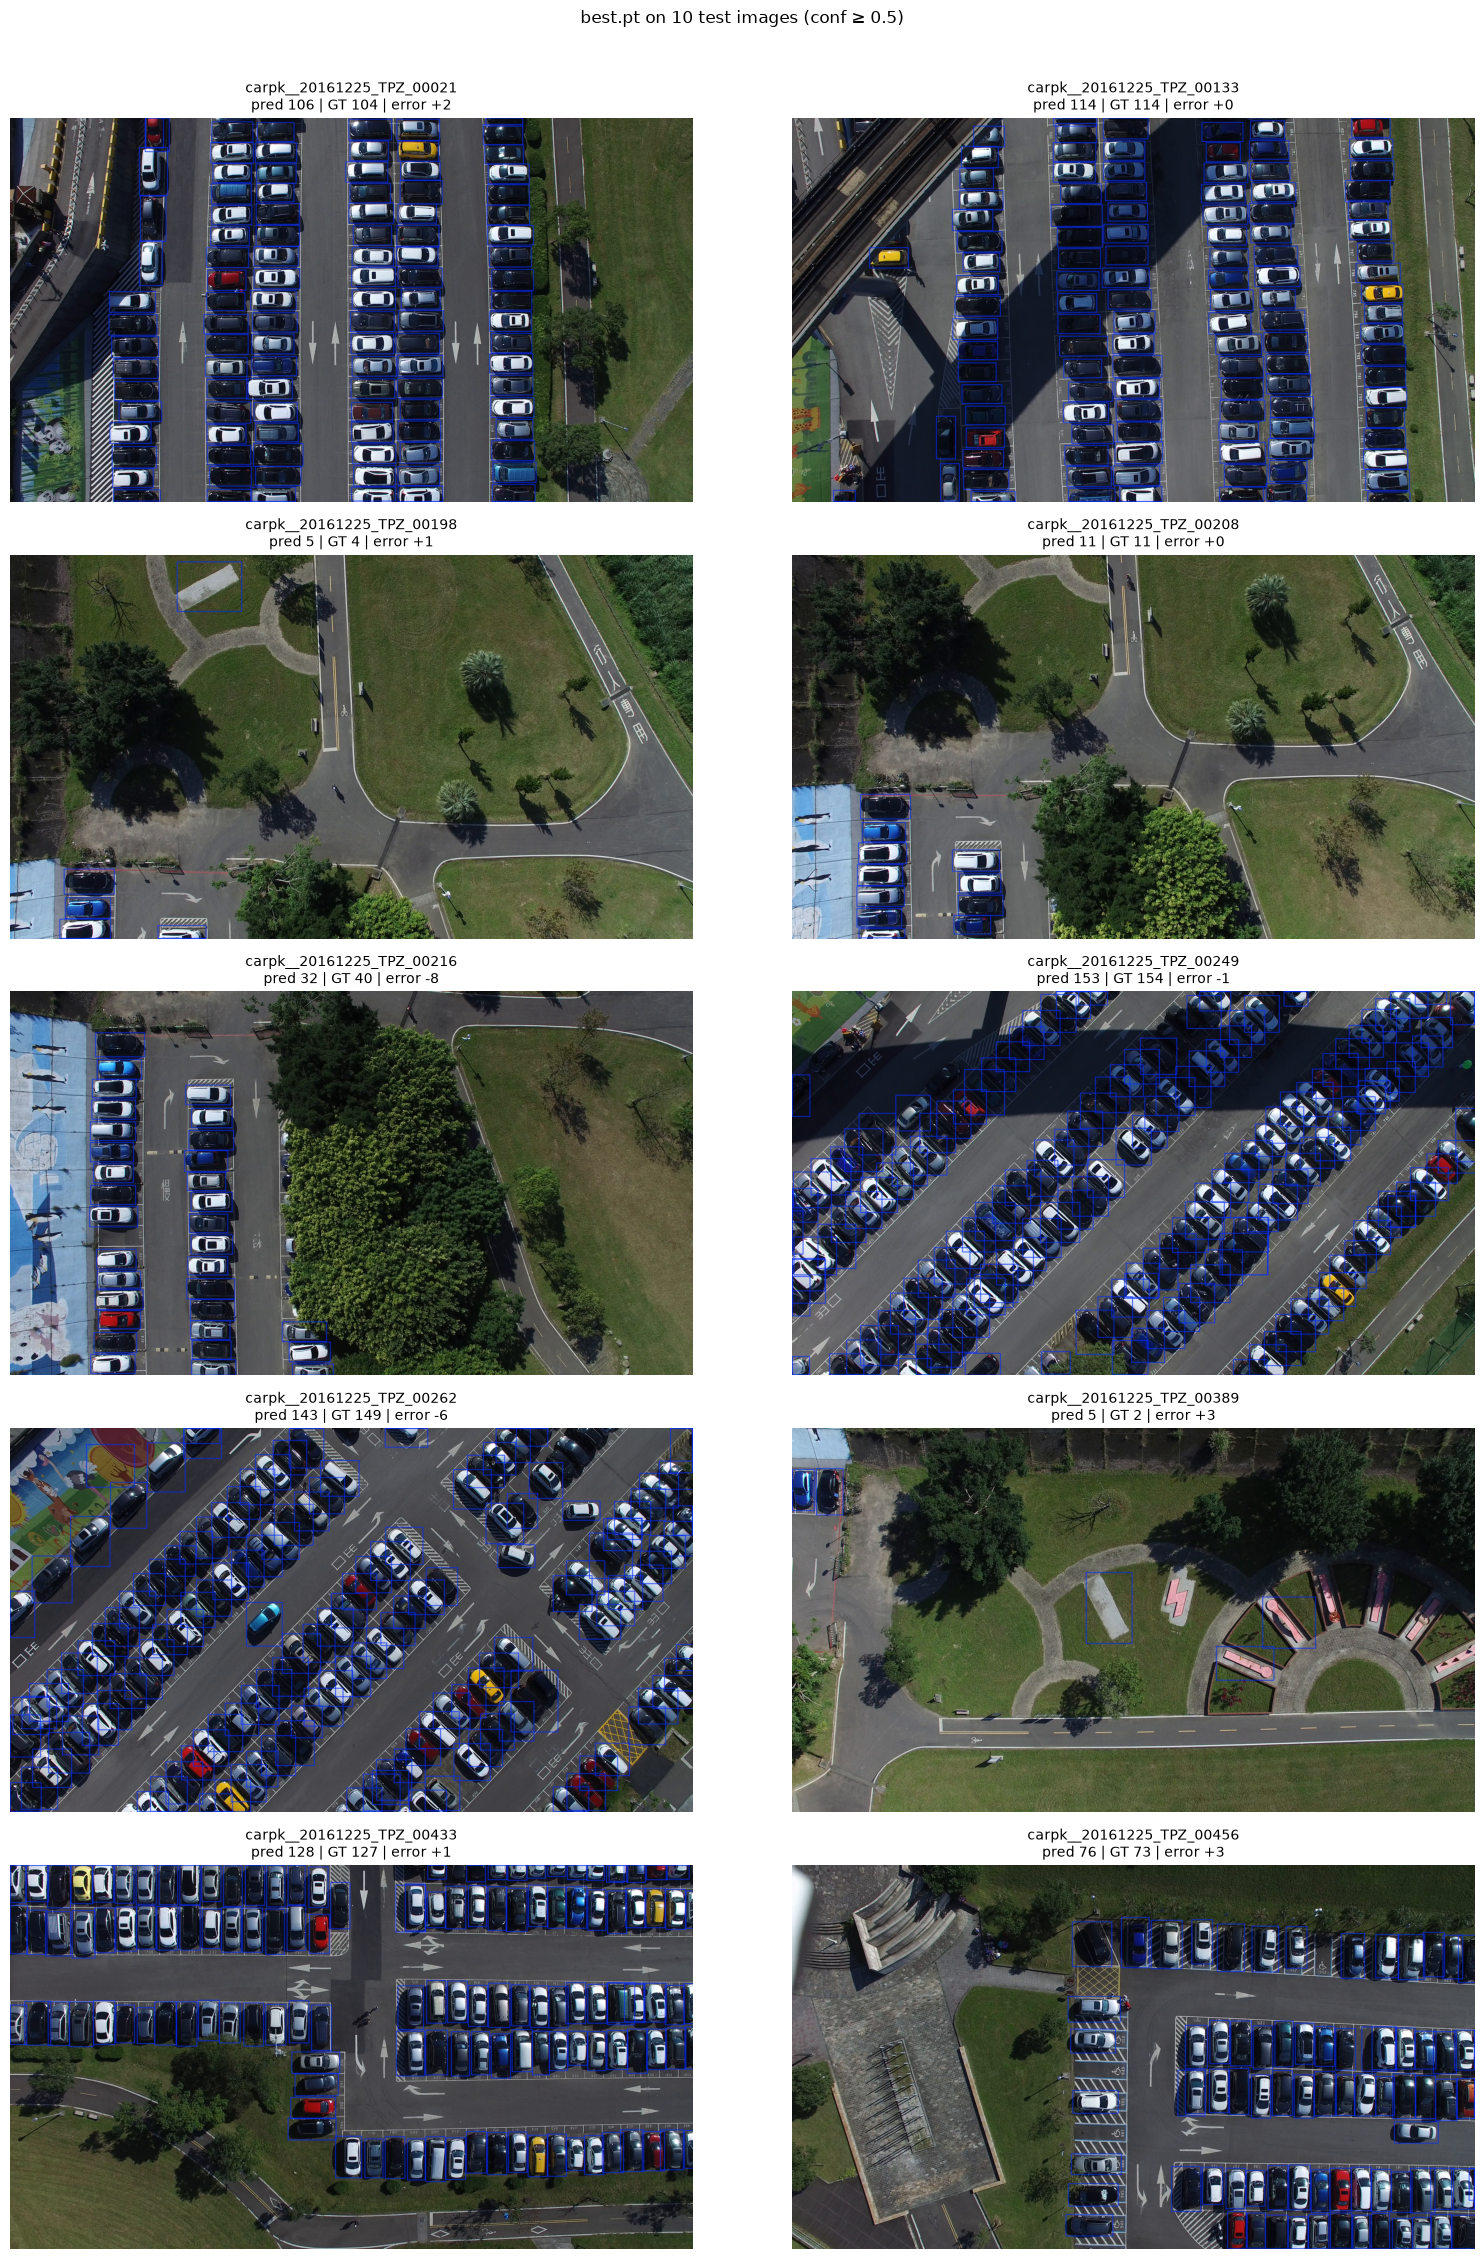

count MAE 2.50 | RMSE 3.54 over 10 images


,image,gt,pred,error
0,carpk__20161225_TPZ_00021,104,106,2
1,carpk__20161225_TPZ_00133,114,114,0
2,carpk__20161225_TPZ_00198,4,5,1
3,carpk__20161225_TPZ_00208,11,11,0
4,carpk__20161225_TPZ_00216,40,32,-8
5,carpk__20161225_TPZ_00249,154,153,-1
6,carpk__20161225_TPZ_00262,149,143,-6
7,carpk__20161225_TPZ_00389,2,5,3
8,carpk__20161225_TPZ_00433,127,128,1
9,carpk__20161225_TPZ_00456,73,76,3


In [14]:
best_new = "/home/mariusz_godlewski/car_recognition/runs/train/full/weights/best.pt"    # or whichever wins in the summary
tuned = float(result["summary"].loc["reference", "tuned conf"])
full_run.show_predictions(best_new, n=10, split="test", seed=0, conf=tuned)

In [4]:
compare.lots_per_split()

split,train,val,test
lot,,,
carpk:GF1,366,32,0
carpk:GF2,312,36,0
carpk:NTU,214,29,0
carpk:TPZ,0,0,459
pucpr,88,12,25
